# Klasifikasi Jenis Sampah Menggunakan Convolutional Neural Network (CNN) dengan Backpropagation

Disusun oleh:
1. Alfian Anggara Putra Afandy (181231043)
2. Bintang Cahya Putra Gunawan (181231061)

Program Studi S-1 Matematika, Departemen Matematika, Fakultas Sains dan Teknologi, Universitas Airlangga, 2026

---

Klasifikasi citra sampah ke dalam dua kelas, yaitu **organik** ($t = 0$) dan **anorganik** ($t = 1$).

## 1. Import Library

In [1]:
import os
import glob
import json
import time
import random
import shutil
import zipfile

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from numpy.lib.stride_tricks import sliding_window_view

np.set_printoptions(precision=4, suppress=True, linewidth=110)
plt.rcParams['figure.dpi'] = 110
print('Library berhasil diimport.')

Library berhasil diimport.


## 2. Parameter Penelitian

In [2]:
SEED = 42

# Data
JUMLAH_PER_KELAS = 11111       # jumlah citra per kelas
PROPORSI_LATIH   = 0.8         # 80% data latih, 20% data uji

# Citra dan arsitektur CNN
UKURAN        = 64             # ukuran citra 64 x 64 piksel
KANAL         = 3              # banyak kanal citra masukan
JUMLAH_KERNEL = 8
UKURAN_KERNEL = 3
STRIDE        = 1
PADDING       = (UKURAN_KERNEL - 1) // 2
HIDDEN        = 16

# Pelatihan
ALPHA           = 0.01         # learning rate
ALPHA_KONVOLUSI = 0.001        # learning rate lapisan konvolusi
ALPHA_TURUN     = 0.8          # learning rate dikalikan nilai ini setiap epoch
LAMBDA_L2       = 0.01         # regularisasi L2 pada bobot hidden layer
AUGMENTASI_FLIP = True         # citra latih dibalik horizontal secara acak
EPSILON         = 0.05         # batas error
E_MAKS          = 10             # maksimum epoch
THRESHOLD       = 0.5          # y >= 0,5 -> anorganik, y < 0,5 -> organik

NAMA_KELAS = {0: 'Organik', 1: 'Anorganik'}
random.seed(SEED)
np.random.seed(SEED)

print('Parameter penelitian:')
print(f'  Data              : {JUMLAH_PER_KELAS} citra per kelas, latih {PROPORSI_LATIH:.0%} : uji {1 - PROPORSI_LATIH:.0%}')
print(f'  Konvolusi         : {JUMLAH_KERNEL} kernel {UKURAN_KERNEL} x {UKURAN_KERNEL}, stride {STRIDE}, padding {PADDING}')
print(f'  Max pooling       : 2 x 2, stride 2')
print(f'  Fully connected   : {HIDDEN} hidden (ReLU), 1 output (sigmoid)')
print(f'  alpha = {ALPHA}, lambda L2 = {LAMBDA_L2}, epsilon = {EPSILON}, E_maks = {E_MAKS}')
print(f'  alpha konvolusi   : {ALPHA_KONVOLUSI}')

Parameter penelitian:
  Data              : 11111 citra per kelas, latih 80% : uji 20%
  Konvolusi         : 8 kernel 3 x 3, stride 1, padding 1
  Max pooling       : 2 x 2, stride 2
  Fully connected   : 16 hidden (ReLU), 1 output (sigmoid)
  alpha = 0.01, lambda L2 = 0.01, epsilon = 0.05, E_maks = 10
  alpha konvolusi   : 0.001


## 3. Dataset

In [3]:
# kagglehub dan google.colab sudah tersedia di Google Colab
import kagglehub  # pyright: ignore[reportMissingImports]

path_dataset = kagglehub.dataset_download('techsash/waste-classification-data')
print('Dataset tersimpan di:', path_dataset)

Dataset tersimpan di: /root/.cache/kagglehub/datasets/techsash/waste-classification-data/versions/1


In [4]:
def kumpulkan_berkas(root):
    # Seluruh citra di folder TRAIN/O, TRAIN/R, TEST/O, dan TEST/R (tanpa duplikat)
    hasil = {'O': {}, 'R': {}}
    for split in ['TRAIN', 'TEST']:
        for kelas in ['O', 'R']:
            for p in glob.glob(os.path.join(root, '**', split, kelas, '*'), recursive=True):
                if p.lower().endswith(('.jpg', '.jpeg', '.png')):
                    hasil[kelas][(split, os.path.basename(p))] = p
    return {kelas: sorted(isi.values()) for kelas, isi in hasil.items()}

berkas = kumpulkan_berkas(path_dataset)
total_asli = len(berkas['O']) + len(berkas['R'])

print('Komposisi dataset:')
print(f'  Organik   (O) : {len(berkas["O"]):>6} citra')
print(f'  Anorganik (R) : {len(berkas["R"]):>6} citra')
print(f'  Total         : {total_asli:>6} citra')

Komposisi dataset:
  Organik   (O) :  13966 citra
  Anorganik (R) :  11111 citra
  Total         :  25077 citra


In [5]:
pengacak = random.Random(SEED)
sampel = {
    0: pengacak.sample(berkas['O'], JUMLAH_PER_KELAS),   # organik, t = 0
    1: pengacak.sample(berkas['R'], JUMLAH_PER_KELAS),   # anorganik, t = 1
}
n_latih = int(JUMLAH_PER_KELAS * PROPORSI_LATIH)

data_latih, data_uji = [], []
for t in [0, 1]:
    data_latih += [(p, t) for p in sampel[t][:n_latih]]
    data_uji += [(p, t) for p in sampel[t][n_latih:]]
pengacak.shuffle(data_latih)
pengacak.shuffle(data_uji)
assert not ({p for p, _ in data_latih} & {p for p, _ in data_uji})

def hitung(data, t):
    return sum(1 for _, label in data if label == t)

print(f'Data dipakai: {len(data_latih) + len(data_uji)} citra ({JUMLAH_PER_KELAS} per kelas)\n')
print(f'{"Kelas":<12}{"Target t":>9}{"Latih":>9}{"Uji":>8}{"Total":>9}')
print('-' * 47)
for t in [0, 1]:
    a, b = hitung(data_latih, t), hitung(data_uji, t)
    print(f'{NAMA_KELAS[t]:<12}{t:>9}{a:>9}{b:>8}{a + b:>9}')
print('-' * 47)
print(f'{"Total":<12}{"":>9}{len(data_latih):>9}{len(data_uji):>8}{len(data_latih) + len(data_uji):>9}')
print('\nTidak ada citra yang sama antara data latih dan data uji.')

Data dipakai: 22222 citra (11111 per kelas)

Kelas        Target t    Latih     Uji    Total
-----------------------------------------------
Organik             0     8888    2223    11111
Anorganik           1     8888    2223    11111
-----------------------------------------------
Total                    17776    4446    22222

Tidak ada citra yang sama antara data latih dan data uji.


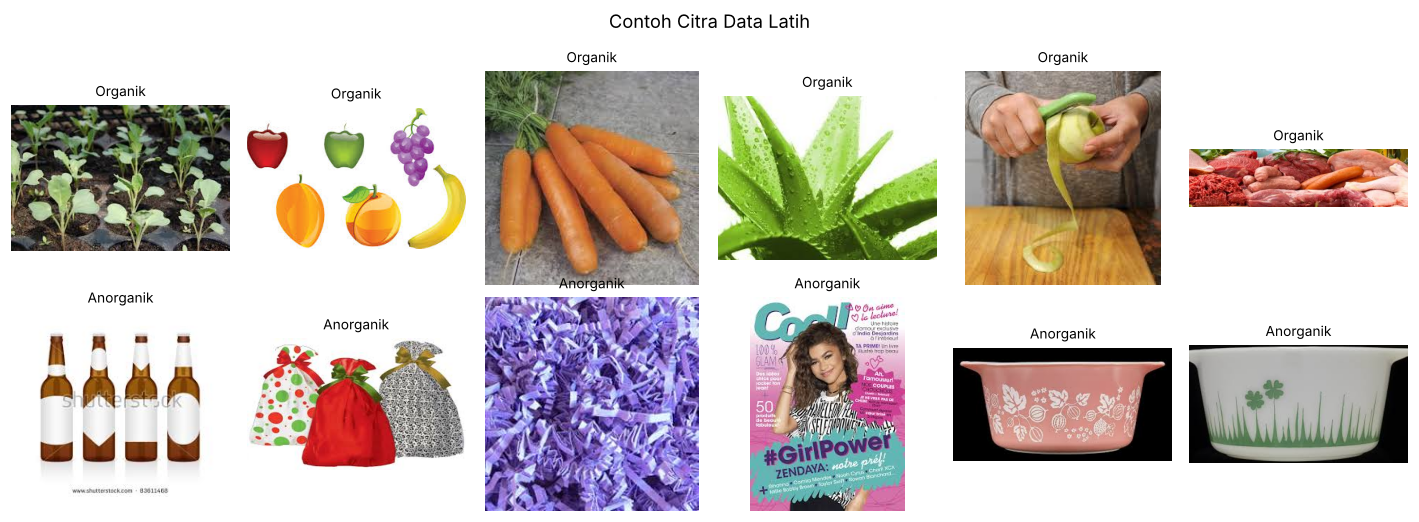

In [6]:
fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
for baris, t in enumerate([0, 1]):
    contoh_kelas = [p for p, label in data_latih if label == t][:6]
    for ax, p in zip(axes[baris], contoh_kelas):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(NAMA_KELAS[t], fontsize=9)
        ax.axis('off')
fig.suptitle('Contoh Citra Data Latih', fontsize=12)
plt.tight_layout()
plt.show()

## 4. Pengolahan Citra

In [7]:
def muat_citra(sumber):
    img = Image.open(sumber)
    img = ImageOps.exif_transpose(img)
    if img.mode in ('RGBA', 'LA') or (img.mode == 'P' and 'transparency' in img.info):
        img = img.convert('RGBA')
        latar = Image.new('RGBA', img.size, (255, 255, 255, 255))
        img = Image.alpha_composite(latar, img)
    return img.convert('RGB')

def resize_citra(img, ukuran=UKURAN):
    return img.resize((ukuran, ukuran), Image.BILINEAR)

def normalisasi(arr):
    return arr / 255.0

def praproses(sumber):
    # Citra -> matriks input I berukuran (KANAL, 64, 64) dengan elemen di [0, 1]
    arr = np.asarray(resize_citra(muat_citra(sumber)), dtype=np.float64)
    return normalisasi(arr.transpose(2, 0, 1))

def olah_semua(data):
    X = np.zeros((len(data), KANAL, UKURAN, UKURAN), dtype=np.float32)
    t = np.zeros(len(data), dtype=int)
    for i, (p, label) in enumerate(data):
        X[i] = praproses(p)
        t[i] = label
    return X, t

mulai = time.time()
X_latih, t_latih = olah_semua(data_latih)
X_uji, t_uji = olah_semua(data_uji)
print(f'Pengolahan citra selesai dalam {time.time() - mulai:.1f} detik.')
print(f'  Data latih : {len(X_latih)} citra')
print(f'  Data uji   : {len(X_uji)} citra')
print(f'  Rentang nilai piksel: {X_latih.min():.1f} sampai {X_latih.max():.1f}')

Pengolahan citra selesai dalam 36.2 detik.
  Data latih : 17776 citra
  Data uji   : 4446 citra
  Rentang nilai piksel: 0.0 sampai 1.0


## 5. Arsitektur CNN dan Backpropagation

In [8]:
def relu(x):
    return np.maximum(0, x)

def turunan_relu(x):
    return (x > 0).astype(np.float64)

def sigmoid(x):
    x = np.asarray(x, dtype=np.float64)
    return np.where(x >= 0, 1 / (1 + np.exp(-np.abs(x))), np.exp(-np.abs(x)) / (1 + np.exp(-np.abs(x))))

def bce(t, y):
    y = np.clip(y, 1e-7, 1 - 1e-7)
    return float(-(t * np.log(y) + (1 - t) * np.log(1 - y)))

def zero_padding(I, q=PADDING):
    return np.pad(I, ((0, 0), (q, q), (q, q)), mode='constant', constant_values=0)

def konvolusi(I_pad, K, bc, s=STRIDE):
    k = K.shape[-1]
    jendela = sliding_window_view(I_pad, (k, k), axis=(1, 2))[:, ::s, ::s]   # (kanal, H, W, k, k)
    C = np.einsum('cijuv,ncuv->nij', jendela, K) + bc[:, None, None]       # (jumlah_kernel, H, W)
    return C, jendela

def max_pooling(R):
    n, H, W = R.shape
    blok = R.reshape(n, H // 2, 2, W // 2, 2).transpose(0, 1, 3, 2, 4).reshape(n, H // 2, W // 2, 4)
    posisi = blok.argmax(axis=-1)
    P = np.take_along_axis(blok, posisi[..., None], axis=-1)[..., 0]
    return P, posisi

def kembalikan_pooling(dP, posisi):
    n, h, w = dP.shape
    blok = np.zeros((n, h, w, 4))
    np.put_along_axis(blok, posisi[..., None], dP[..., None], axis=-1)
    return blok.reshape(n, h, w, 2, 2).transpose(0, 1, 3, 2, 4).reshape(n, 2 * h, 2 * w)

def umpan_maju(I, param):
    C, jendela = konvolusi(zero_padding(I), param['K'], param['bc'])   # konvolusi
    R = relu(C)                                                          # ReLU
    P, posisi = max_pooling(R)                                           # max pooling
    x = P.reshape(-1)                                                    # flatten
    z_in = param['v0'] + x @ param['V']                                  # hidden layer
    z = relu(z_in)
    y_in = param['w0'] + z @ param['w']                                  # output layer
    y = float(sigmoid(y_in))
    return {'jendela': jendela, 'C': C, 'P': P, 'posisi': posisi, 'x': x, 'z_in': z_in, 'z': z, 'y_in': float(y_in), 'y': y}

def prediksi_kelas(y):
    return 1 if y >= THRESHOLD else 0

print('Fungsi umpan maju berhasil didefinisikan.')

Fungsi umpan maju berhasil didefinisikan.


In [9]:
def propagasi_balik(cache, t, param, alpha=ALPHA, alpha_k=ALPHA_KONVOLUSI, lam=LAMBDA_L2):
    # Unit output
    delta_k = t - cache['y']
    dw = alpha * delta_k * cache['z']
    dw0 = alpha * delta_k
    # Hidden unit (dengan regularisasi L2 pada v_ij)
    delta_j = delta_k * param['w'] * turunan_relu(cache['z_in'])
    dV = alpha * (np.outer(cache['x'], delta_j) - lam * param['V'])
    dv0 = alpha * delta_j
    # Flatten -> max pooling -> ReLU
    dP = (param['V'] @ delta_j).reshape(cache['P'].shape)
    dR = kembalikan_pooling(dP, cache['posisi'])
    dC = dR * turunan_relu(cache['C'])
    # Kernel dan bias konvolusi
    dK = alpha_k * np.einsum('nij,cijuv->ncuv', dC, cache['jendela'])
    dbc = alpha_k * dC.sum(axis=(1, 2))
    return {'K': dK, 'bc': dbc, 'V': dV, 'v0': dv0, 'w': dw, 'w0': dw0}

def perbarui_parameter(param, koreksi):
    for nama in param:
        param[nama] = param[nama] + koreksi[nama]
    return param

def inisialisasi_parameter(seed=SEED):
    rng = np.random.default_rng(seed)
    acak = lambda *ukuran: rng.uniform(-0.5, 0.5, size=ukuran)
    n_flatten = JUMLAH_KERNEL * (UKURAN // 2) * (UKURAN // 2)
    return {
        'K':  acak(JUMLAH_KERNEL, KANAL, UKURAN_KERNEL, UKURAN_KERNEL),
        'bc': acak(JUMLAH_KERNEL),
        'V':  acak(n_flatten, HIDDEN),
        'v0': acak(HIDDEN),
        'w':  acak(HIDDEN),
        'w0': float(acak(1)[0]),
    }

param = inisialisasi_parameter()
jumlah = {nama: int(np.size(nilai)) for nama, nilai in param.items()}
print(f'Lapisan konvolusi : {jumlah["K"] + jumlah["bc"]:>7} parameter')
print(f'Hidden layer      : {jumlah["V"] + jumlah["v0"]:>7} parameter')
print(f'Output layer      : {jumlah["w"] + jumlah["w0"]:>7} parameter')
print(f'Total             : {sum(jumlah.values()):>7} parameter')

Lapisan konvolusi :     224 parameter
Hidden layer      :  131088 parameter
Output layer      :      17 parameter
Total             :  131329 parameter


In [10]:
# Pengecekan gradien: koreksi dari program dibandingkan dengan turunan numerik
def cek_gradien(I, t, param, lam=LAMBDA_L2, h=1e-7):
    koreksi = propagasi_balik(umpan_maju(I, param), t, param, alpha=1.0, alpha_k=1.0, lam=lam)
    rng = np.random.default_rng(0)
    selisih_maks = 0.0
    for nama in ['K', 'bc', 'V', 'v0', 'w', 'w0']:
        if nama == 'w0':
            daftar = [None]
        else:
            kandidat = np.argwhere(np.abs(koreksi[nama]) > 1e-9)
            pilih = rng.choice(len(kandidat), size=min(2, len(kandidat)), replace=False)
            daftar = [tuple(int(i) for i in kandidat[p]) for p in pilih]
        for indeks in daftar:
            nilai_awal = param['w0'] if indeks is None else param[nama][indeks]
            def L_dengan(nilai):
                if indeks is None:
                    param['w0'] = nilai
                else:
                    param[nama][indeks] = nilai
                return bce(t, umpan_maju(I, param)['y']) + lam / 2 * float(np.sum(param['V'] ** 2))
            numerik = -(L_dengan(nilai_awal + h) - L_dengan(nilai_awal - h)) / (2 * h)
            L_dengan(nilai_awal)
            program = koreksi[nama] if indeks is None else koreksi[nama][indeks]
            selisih_maks = max(selisih_maks, abs(program - numerik) / max(1e-12, abs(program) + abs(numerik)))
    return selisih_maks

param_cek = {nama: nilai * 0.1 for nama, nilai in inisialisasi_parameter(seed=7).items()}
selisih = cek_gradien(X_latih[0].astype(np.float64), t_latih[0], param_cek)
print(f'Selisih relatif terbesar: {selisih:.2e}')
print('Propagasi balik BENAR.' if selisih < 1e-4 else 'Periksa kembali rumus propagasi balik.')

Selisih relatif terbesar: 2.42e-06
Propagasi balik BENAR.


## 6. Pelatihan CNN dengan Backpropagation

In [11]:
param = inisialisasi_parameter()
pengacak_epoch = np.random.default_rng(SEED)
riwayat = {'epoch': [], 'L_rata': [], 'akurasi_latih': []}

print(f'Pelatihan dimulai: {len(X_latih)} citra latih, E_maks = {E_MAKS}\n')
mulai_latih = time.time()
epoch = 1
while epoch <= E_MAKS:
    mulai_epoch = time.time()
    faktor = ALPHA_TURUN ** (epoch - 1)                         # learning rate mengecil setiap epoch
    urutan = pengacak_epoch.permutation(len(X_latih))
    dibalik = pengacak_epoch.random(len(X_latih)) < 0.5
    total_L, benar = 0.0, 0
    for n in urutan:
        I = X_latih[n].astype(np.float64)
        if AUGMENTASI_FLIP and dibalik[n]:
            I = I[:, :, ::-1]                                   # flip horizontal
        cache = umpan_maju(I, param)
        total_L += bce(t_latih[n], cache['y'])
        benar += int(prediksi_kelas(cache['y']) == t_latih[n])
        param = perbarui_parameter(param, propagasi_balik(cache, t_latih[n], param, alpha=ALPHA * faktor, alpha_k=ALPHA_KONVOLUSI * faktor))

    L_rata = total_L / len(X_latih)
    akurasi_latih = benar / len(X_latih)
    riwayat['epoch'].append(epoch)
    riwayat['L_rata'].append(L_rata)
    riwayat['akurasi_latih'].append(akurasi_latih)
    print(f'Epoch {epoch:>2}/{E_MAKS} | L rata-rata = {L_rata:.4f} | akurasi latih = {akurasi_latih * 100:6.2f}% | '
          f'{time.time() - mulai_epoch:.1f} detik')
    if L_rata < EPSILON:
        print(f'L rata-rata < epsilon ({EPSILON}), pelatihan dihentikan.')
        break
    epoch += 1

epoch_terakhir = riwayat['epoch'][-1]
waktu_latih = time.time() - mulai_latih
print(f'\nPelatihan selesai di epoch {epoch_terakhir}. Total waktu: {waktu_latih / 60:.1f} menit')

param['w0'] = float(param['w0'])
np.savez('parameter_optimal.npz', **param)
print('Parameter optimal disimpan ke parameter_optimal.npz')

Pelatihan dimulai: 17776 citra latih, E_maks = 10

Epoch  1/10 | L rata-rata = 0.5012 | akurasi latih =  76.45% | 71.5 detik
Epoch  2/10 | L rata-rata = 0.4382 | akurasi latih =  80.88% | 70.8 detik
Epoch  3/10 | L rata-rata = 0.4252 | akurasi latih =  81.64% | 73.1 detik
Epoch  4/10 | L rata-rata = 0.4131 | akurasi latih =  81.98% | 71.4 detik
Epoch  5/10 | L rata-rata = 0.4052 | akurasi latih =  82.58% | 70.9 detik
Epoch  6/10 | L rata-rata = 0.3981 | akurasi latih =  82.94% | 67.3 detik
Epoch  7/10 | L rata-rata = 0.3894 | akurasi latih =  83.20% | 68.3 detik
Epoch  8/10 | L rata-rata = 0.3808 | akurasi latih =  83.70% | 67.4 detik
Epoch  9/10 | L rata-rata = 0.3764 | akurasi latih =  84.05% | 71.6 detik
Epoch 10/10 | L rata-rata = 0.3685 | akurasi latih =  84.34% | 68.8 detik

Pelatihan selesai di epoch 10. Total waktu: 11.7 menit
Parameter optimal disimpan ke parameter_optimal.npz


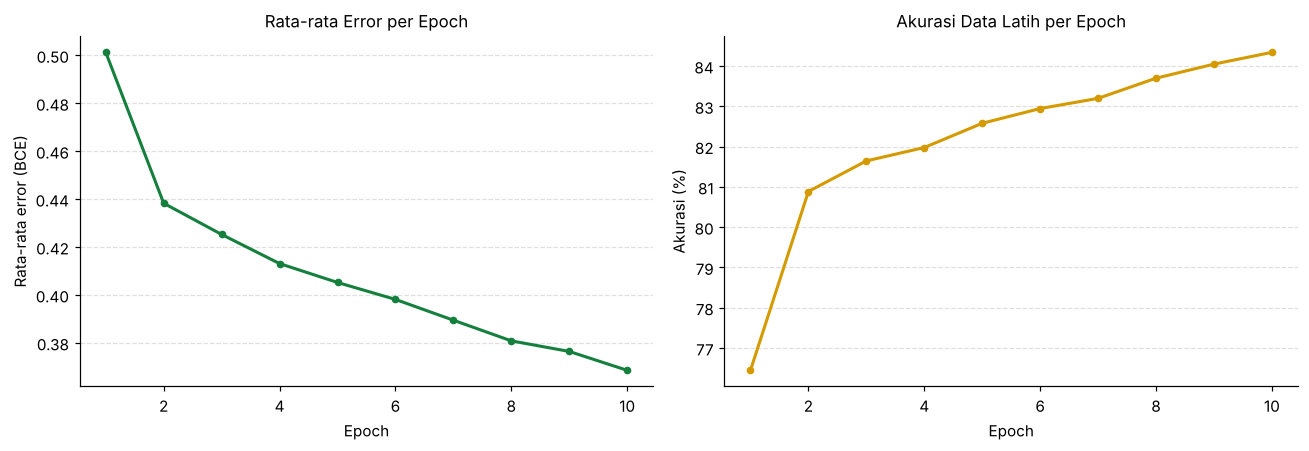

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(riwayat['epoch'], riwayat['L_rata'], 'o-', color='#15803D', linewidth=2, markersize=4)
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Rata-rata error (BCE)')
ax1.set_title('Rata-rata Error per Epoch', fontsize=11)
ax2.plot(riwayat['epoch'], np.array(riwayat['akurasi_latih']) * 100, 'o-', color='#D49A00', linewidth=2, markersize=4)
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Akurasi (%)')
ax2.set_title('Akurasi Data Latih per Epoch', fontsize=11)
for ax in (ax1, ax2):
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.show()

## 7. Pengujian dan Evaluasi Model

In [13]:
mulai = time.time()
y_uji = np.array([umpan_maju(I.astype(np.float64), param)['y'] for I in X_uji])
t_prediksi = np.array([prediksi_kelas(y) for y in y_uji])
print(f'Pengujian {len(X_uji)} citra uji selesai dalam {time.time() - mulai:.1f} detik.\n')

def hitung_evaluasi(t_aktual, t_pred):
    TP = int(np.sum((t_aktual == 1) & (t_pred == 1)))
    TN = int(np.sum((t_aktual == 0) & (t_pred == 0)))
    FP = int(np.sum((t_aktual == 0) & (t_pred == 1)))
    FN = int(np.sum((t_aktual == 1) & (t_pred == 0)))
    akurasi = (TP + TN) / (TP + TN + FP + FN)
    presisi = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1 = 2 * presisi * recall / (presisi + recall) if (presisi + recall) > 0 else 0.0
    return TP, TN, FP, FN, akurasi, presisi, recall, f1

TP, TN, FP, FN, akurasi, presisi, recall, f1 = hitung_evaluasi(t_uji, t_prediksi)
print('Confusion matrix (anorganik = kelas positif):')
print(f'  TP = {TP}, TN = {TN}, FP = {FP}, FN = {FN}\n')
print(f'  Accuracy  = ({TP} + {TN}) / ({TP} + {TN} + {FP} + {FN}) = {akurasi * 100:.2f}%')
print(f'  Precision = {TP} / ({TP} + {FP}) = {presisi * 100:.2f}%')
print(f'  Recall    = {TP} / ({TP} + {FN}) = {recall * 100:.2f}%')
print(f'  F1-score  = 2 x {presisi:.4f} x {recall:.4f} / ({presisi:.4f} + {recall:.4f}) = {f1 * 100:.2f}%')

Pengujian 4446 citra uji selesai dalam 9.2 detik.

Confusion matrix (anorganik = kelas positif):
  TP = 1783, TN = 1899, FP = 324, FN = 440

  Accuracy  = (1783 + 1899) / (1783 + 1899 + 324 + 440) = 82.82%
  Precision = 1783 / (1783 + 324) = 84.62%
  Recall    = 1783 / (1783 + 440) = 80.21%
  F1-score  = 2 x 0.8462 x 0.8021 / (0.8462 + 0.8021) = 82.36%


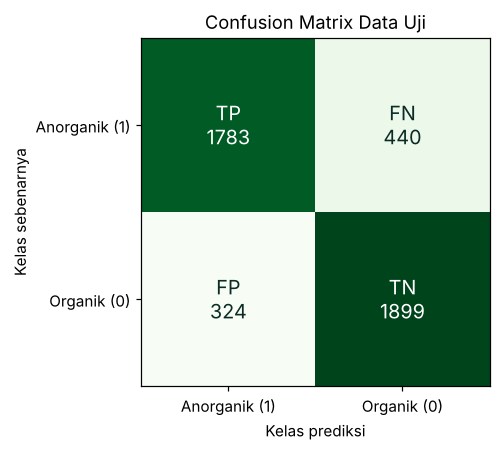

In [14]:
cm = np.array([[TP, FN], [FP, TN]])
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.imshow(cm, cmap='Greens')
label = ['Anorganik (1)', 'Organik (0)']
ax.set_xticks([0, 1]); ax.set_xticklabels(label)
ax.set_yticks([0, 1]); ax.set_yticklabels(label)
nama_sel = [['TP', 'FN'], ['FP', 'TN']]
for i in range(2):
    for j in range(2):
        warna = 'white' if cm[i, j] > cm.max() / 2 else '#0B2B26'
        ax.text(j, i, f'{nama_sel[i][j]}\n{cm[i, j]}', ha='center', va='center', fontsize=13, color=warna)
ax.set_xlabel('Kelas prediksi'); ax.set_ylabel('Kelas sebenarnya')
ax.set_title('Confusion Matrix Data Uji', fontsize=12)
plt.tight_layout()
plt.show()

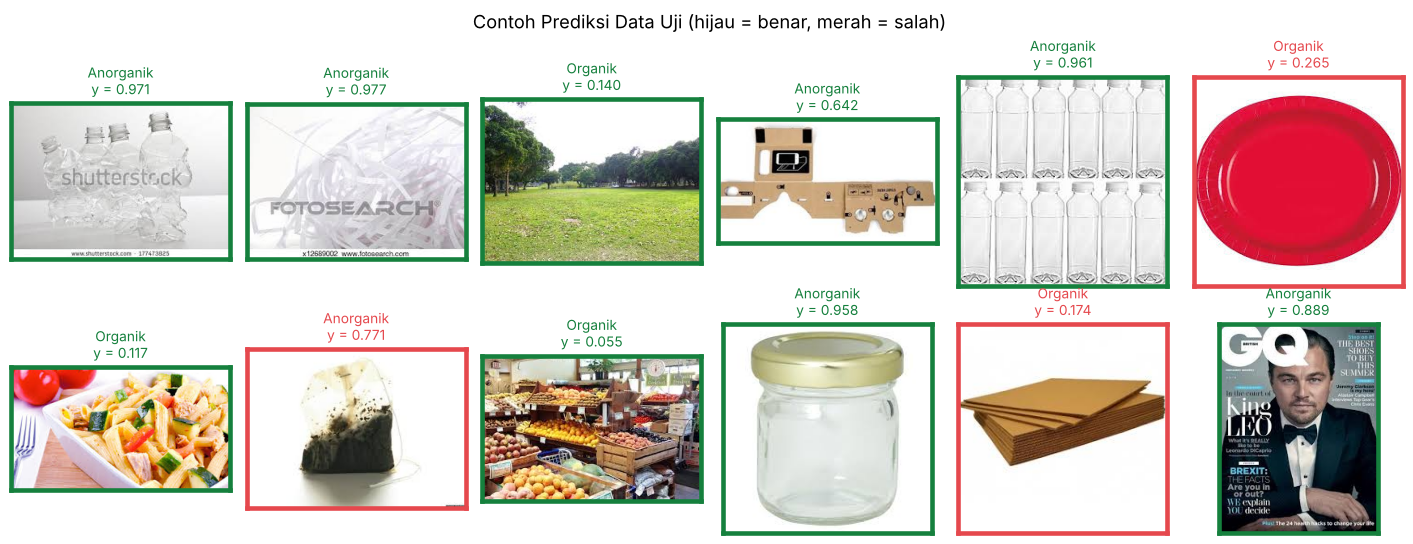

In [15]:
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, n in zip(axes.ravel(), range(12)):
    path_n, t_n = data_uji[n]
    ax.imshow(Image.open(path_n).convert('RGB'))
    benar = t_prediksi[n] == t_n
    warna = '#15803D' if benar else '#E5484D'
    ax.set_title(f'{NAMA_KELAS[t_prediksi[n]]}\ny = {y_uji[n]:.3f}', fontsize=9, color=warna)
    for sisi in ax.spines.values():
        sisi.set_edgecolor(warna); sisi.set_linewidth(3)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Contoh Prediksi Data Uji (hijau = benar, merah = salah)', fontsize=12)
plt.tight_layout()
plt.show()

## 8. Ekspor Model ke Website PILAH

In [16]:
JUMLAH_CONTOH_PER_KELAS = 3
folder_ekspor = 'pilah_model_web'
shutil.rmtree(folder_ekspor, ignore_errors=True)
os.makedirs(f'{folder_ekspor}/model', exist_ok=True)
os.makedirs(f'{folder_ekspor}/samples', exist_ok=True)

# model.bin: float32 little-endian dengan urutan K, bc, V, v0, w, w0
urutan_param = ['K', 'bc', 'V', 'v0', 'w', 'w0']
blob = np.concatenate([np.asarray(param[n], dtype='<f4').reshape(-1) for n in urutan_param]).tobytes()
with open(f'{folder_ekspor}/model/model.bin', 'wb') as f:
    f.write(blob)
param_web = {n: np.asarray(param[n], dtype=np.float32).astype(np.float64) for n in urutan_param}
param_web['w0'] = float(param_web['w0'])

# Contoh foto untuk website + golden test (nilai y pembanding)
contoh = []
for t in [1, 0]:
    contoh += [n for n in range(len(data_uji)) if t_uji[n] == t and t_prediksi[n] == t][:JUMLAH_CONTOH_PER_KELAS]
manifest, golden = [], []
for nomor, n in enumerate(contoh, start=1):
    path_n, t_n = data_uji[n]
    nama_berkas = f'contoh-{nomor}{os.path.splitext(path_n)[1].lower()}'
    shutil.copy(path_n, f'{folder_ekspor}/samples/{nama_berkas}')
    piksel = np.asarray(resize_citra(muat_citra(path_n))).transpose(2, 0, 1)
    y_n = umpan_maju(piksel / 255.0, param_web)['y']
    manifest.append({'src': f'/samples/{nama_berkas}', 'label': f'Contoh {NAMA_KELAS[t_n].lower()} {nomor}', 'kind': NAMA_KELAS[t_n].lower()})
    golden.append({'name': nama_berkas, 'file': f'/samples/{nama_berkas}', 't': int(t_n), 'input': piksel.astype(int).reshape(-1).tolist(), 'y': float(y_n)})
with open(f'{folder_ekspor}/samples/manifest.json', 'w') as f:
    json.dump(manifest, f, indent=2)
with open(f'{folder_ekspor}/model/golden.json', 'w') as f:
    json.dump(golden, f)

# meta.json
meta = {
    'version': time.strftime('%Y.%m.%d'),
    'inputSize': UKURAN, 'kernels': JUMLAH_KERNEL, 'kernelSize': UKURAN_KERNEL, 'hidden': HIDDEN,
    'channels': KANAL, 'flatten': 'channel-major', 'grayRound': True,
    'threshold': THRESHOLD, 'uncertainBand': 0.1,
    'metrics': {'accuracy': akurasi, 'precision': presisi, 'recall': recall, 'f1': f1,
                'testSize': int(len(X_uji)), 'tp': TP, 'tn': TN, 'fp': FP, 'fn': FN},
    'data': {'perClass': JUMLAH_PER_KELAS, 'used': int(len(X_latih) + len(X_uji)),
             'train': int(len(X_latih)), 'test': int(len(X_uji))},
    'training': {'trainSize': int(len(X_latih)), 'epochs': int(epoch_terakhir), 'alpha': ALPHA,
                 'epsilon': EPSILON, 'eMax': E_MAKS, 'seconds': round(waktu_latih, 1),
                 'l2': LAMBDA_L2, 'flip': bool(AUGMENTASI_FLIP),
                 'alphaDecay': ALPHA_TURUN,
                 'lossHistory': [round(float(v), 5) for v in riwayat['L_rata']],
                 'accHistory': [round(float(v), 5) for v in riwayat['akurasi_latih']]},
    'trainedAt': time.strftime('%Y-%m-%d'),
}
with open(f'{folder_ekspor}/model/meta.json', 'w') as f:
    json.dump(meta, f, indent=2)

# Cek ulang: baca kembali model.bin, y harus sama
data_bin = np.frombuffer(open(f'{folder_ekspor}/model/model.bin', 'rb').read(), dtype='<f4').astype(np.float64)
o, param_baca = 0, {}
for n in urutan_param:
    ukuran = int(np.size(param[n]))
    param_baca[n] = data_bin[o:o + ukuran].reshape(np.shape(param[n]))
    o += ukuran
param_baca['w0'] = float(param_baca['w0'])
for g in golden:
    I = np.array(g['input'], dtype=np.float64).reshape(KANAL, UKURAN, UKURAN) / 255.0
    assert abs(umpan_maju(I, param_baca)['y'] - g['y']) < 1e-9

with zipfile.ZipFile('pilah_model_web.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for root, _, nama_nama in os.walk(folder_ekspor):
        for nama in sorted(nama_nama):
            p = os.path.join(root, nama)
            z.write(p, os.path.relpath(p, folder_ekspor))

print('Isi pilah_model_web.zip:')
with zipfile.ZipFile('pilah_model_web.zip') as z:
    for info in z.infolist():
        print(f'  {info.filename:<28}{info.file_size / 1024:>8.1f} KB')
print('\nmodel.bin sudah dicek ulang dan siap dipakai website.')

from google.colab import files  # pyright: ignore[reportMissingImports]
files.download('pilah_model_web.zip')

Isi pilah_model_web.zip:
  model/golden.json              349.9 KB
  model/meta.json                  1.1 KB
  model/model.bin                513.0 KB
  samples/contoh-1.jpg             5.1 KB
  samples/contoh-2.jpg             5.4 KB
  samples/contoh-3.jpg             5.1 KB
  samples/contoh-4.jpg            10.2 KB
  samples/contoh-5.jpg            15.4 KB
  samples/contoh-6.jpg            15.8 KB
  samples/manifest.json            0.6 KB

model.bin sudah dicek ulang dan siap dipakai website.


## 9. Kesimpulan

In [17]:
print('=' * 62)
print('RINGKASAN KLASIFIKASI JENIS SAMPAH DENGAN CNN DAN BACKPROPAGATION')
print('=' * 62)
print(f'Dataset          : Waste Classification Data (Kaggle), {total_asli} citra')
print(f'Data dipakai     : {len(X_latih) + len(X_uji)} citra ({JUMLAH_PER_KELAS} per kelas)')
print(f'Pembagian data   : {len(X_latih)} latih (80%), {len(X_uji)} uji (20%)')
print(f'Arsitektur       : konvolusi {JUMLAH_KERNEL} kernel {UKURAN_KERNEL} x {UKURAN_KERNEL} + ReLU, max pooling 2 x 2,')
print(f'                   hidden {HIDDEN} neuron ReLU, output 1 neuron sigmoid')
print(f'Total parameter  : {sum(int(np.size(v)) for v in param.values())}')
print(f'Pelatihan        : alpha = {ALPHA}, epsilon = {EPSILON}, {epoch_terakhir} epoch, {waktu_latih / 60:.1f} menit')
print(f'L rata-rata akhir: {riwayat["L_rata"][-1]:.4f}')
print('-' * 62)
print(f'Accuracy         : {akurasi * 100:.2f}%')
print(f'Precision        : {presisi * 100:.2f}%')
print(f'Recall           : {recall * 100:.2f}%')
print(f'F1-score         : {f1 * 100:.2f}%')
print('=' * 62)
print(f'\nDari {len(X_uji)} citra uji, {TP + TN} citra diklasifikasikan dengan benar (accuracy {akurasi * 100:.2f}%).')
print(f'Precision {presisi * 100:.2f}%: dari {TP + FP} citra yang diprediksi anorganik, {TP} memang anorganik.')
print(f'Recall {recall * 100:.2f}%: dari {TP + FN} citra anorganik, {TP} berhasil dikenali.')

RINGKASAN KLASIFIKASI JENIS SAMPAH DENGAN CNN DAN BACKPROPAGATION
Dataset          : Waste Classification Data (Kaggle), 25077 citra
Data dipakai     : 22222 citra (11111 per kelas)
Pembagian data   : 17776 latih (80%), 4446 uji (20%)
Arsitektur       : konvolusi 8 kernel 3 x 3 + ReLU, max pooling 2 x 2,
                   hidden 16 neuron ReLU, output 1 neuron sigmoid
Total parameter  : 131329
Pelatihan        : alpha = 0.01, epsilon = 0.05, 10 epoch, 11.7 menit
L rata-rata akhir: 0.3685
--------------------------------------------------------------
Accuracy         : 82.82%
Precision        : 84.62%
Recall           : 80.21%
F1-score         : 82.36%

Dari 4446 citra uji, 3682 citra diklasifikasikan dengan benar (accuracy 82.82%).
Precision 84.62%: dari 2107 citra yang diprediksi anorganik, 1783 memang anorganik.
Recall 80.21%: dari 2223 citra anorganik, 1783 berhasil dikenali.
